# Tugas-03 — Canonical Correlation Analysis (CCA)
**Mata kuliah:** Analisis Multivariat · Pertemuan 11
**Judul kasus:** Hubungan *Faktor Psikologis* dan *Gejala Fisiologis* pada Mahasiswa

---
### Sumber Data
- **Dataset:** *Student Stress Factors: A Comprehensive Analysis*
- **Penulis di Kaggle:** Chhabii (username `rxnach`)
- **URL:** https://www.kaggle.com/datasets/rxnach/student-stress-factors-a-comprehensive-analysis
- **File:** `StressLevelDataset.csv` (1.100 baris × 21 kolom, data survei mahasiswa)
- Dataset ini dikelompokkan oleh penyusunnya ke dalam 5 kelompok faktor (psikologis, fisiologis, lingkungan, akademik, sosial), sehingga pembagian Set X dan Set Y **bukan arbitrer** — mengikuti taksonomi bawaan dataset.


## 0. Setup & Konfigurasi

In [28]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import linear_sum_assignment
from sklearn.cross_decomposition import CCA
from sklearn.model_selection import RepeatedKFold

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RNG = np.random.default_rng(42)

OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

# ---- Konfigurasi analisis ----
CSV_NAME = "StressLevelDataset.csv"
KAGGLE_ID = "rxnach/student-stress-factors-a-comprehensive-analysis"

X_VARS = ["anxiety_level", "self_esteem", "depression"]
Y_VARS = ["headache", "blood_pressure", "sleep_quality", "breathing_problem"]
EXTERNAL_VAR = "stress_level"   # TIDAK dimasukkan ke CCA; dipakai untuk validasi eksternal

ALPHA = 0.05
MIN_R2 = 0.10
MIN_CV = 0.30
N_BOOT, N_PERM = 1000, 2000


### Memuat data

In [29]:
def load_data():
    if os.path.exists(CSV_NAME):
        return pd.read_csv(CSV_NAME)
    try:
        import kagglehub
        path = kagglehub.dataset_download(KAGGLE_ID)
        f = glob.glob(os.path.join(path, "*.csv"))[0]
        return pd.read_csv(f)
    except Exception as e:
        raise FileNotFoundError(
            f"Tidak menemukan {CSV_NAME}. Unduh manual dari https://www.kaggle.com/datasets/{KAGGLE_ID} "
            f"lalu letakkan di folder notebook. (detail: {e})")

df = load_data()
print("Dimensi data :", df.shape)
df.head()

Using Colab cache for faster access to the 'student-stress-factors-a-comprehensive-analysis' dataset.
Dimensi data : (1100, 21)


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1


## Ukuran sampel, missing values, duplikat, tipe data

In [30]:
sub = df[X_VARS + Y_VARS + [EXTERNAL_VAR]].copy()

print(f"Sample size (n) = {len(sub)}")
print(f"p (Set X) = {len(X_VARS)}, q (Set Y) = {len(Y_VARS)}  ->  n/(p+q) = {len(sub)/(len(X_VARS)+len(Y_VARS)):.1f} observasi per variabel")
print("\nMissing values per kolom:")
print(sub.isna().sum().to_string())
print(f"\nTotal missing = {sub.isna().sum().sum()}")
print(f"Baris duplikat = {sub.duplicated().sum()}")
print("\nTipe data:\n", sub.dtypes.to_string())

desc = sub.describe().T
desc["skew"] = sub.skew()
desc["kurtosis"] = sub.kurt()
desc["n_unique"] = sub.nunique()
desc.round(3)

Sample size (n) = 1100
p (Set X) = 3, q (Set Y) = 4  ->  n/(p+q) = 157.1 observasi per variabel

Missing values per kolom:
anxiety_level        0
self_esteem          0
depression           0
headache             0
blood_pressure       0
sleep_quality        0
breathing_problem    0
stress_level         0

Total missing = 0
Baris duplikat = 49

Tipe data:
 anxiety_level        int64
self_esteem          int64
depression           int64
headache             int64
blood_pressure       int64
sleep_quality        int64
breathing_problem    int64
stress_level         int64


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,n_unique
anxiety_level,1100.0,11.064,6.118,0.0,6.0,11.0,16.0,21.0,-0.083,-1.094,22
self_esteem,1100.0,17.777,8.945,0.0,11.0,19.0,26.0,30.0,-0.397,-1.062,31
depression,1100.0,12.555,7.727,0.0,6.0,12.0,19.0,27.0,0.217,-0.989,28
headache,1100.0,2.508,1.409,0.0,1.0,3.0,3.0,5.0,0.270,-0.997,6
blood_pressure,1100.0,2.182,0.834,1.0,1.0,2.0,3.0,3.0,-0.351,-1.474,3
sleep_quality,1100.0,2.660,1.548,0.0,1.0,2.5,4.0,5.0,0.178,-1.322,6
breathing_problem,1100.0,2.754,1.401,0.0,2.0,3.0,4.0,5.0,-0.002,-1.060,6
stress_level,1100.0,0.996,0.822,0.0,0.0,1.0,2.0,2.0,0.007,-1.519,3


Baris sebelum: 1100 | sesudah listwise deletion: 1100


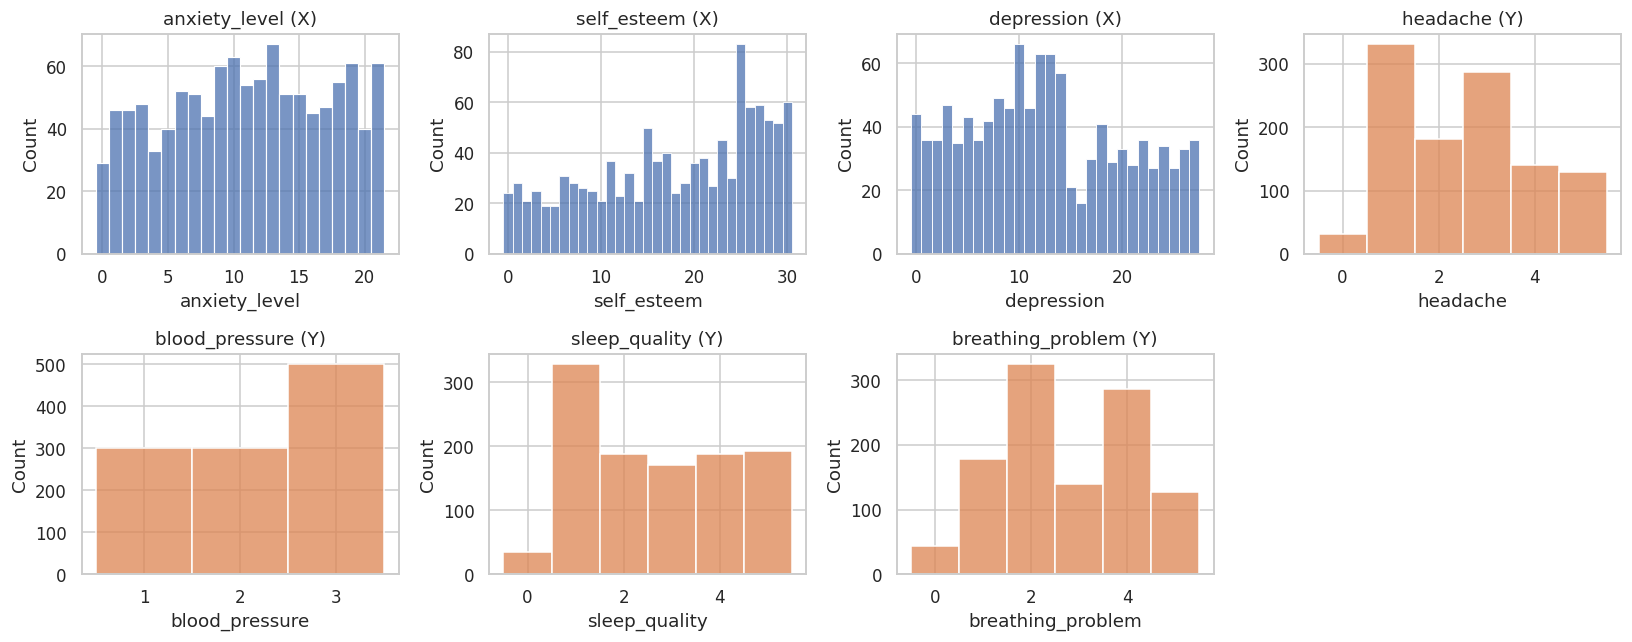

In [31]:
# Penanganan Missing Value
n_before = len(sub)
data = sub.dropna(subset=X_VARS + Y_VARS).reset_index(drop=True)
print(f"Baris sebelum: {n_before} | sesudah listwise deletion: {len(data)}")

# Sebaran tiap variabel
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, v in zip(axes.ravel(), X_VARS + Y_VARS):
    sns.histplot(data[v], discrete=data[v].nunique() < 40, ax=ax,
                 color="#4C72B0" if v in X_VARS else "#DD8452")
    ax.set_title(f"{v} ({'X' if v in X_VARS else 'Y'})")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_distribusi.png", bbox_inches="tight"); plt.show()

### Standarization

In [32]:
print("Rentang skala (min–max) dan simpangan baku:")
print(pd.DataFrame({"min": data[X_VARS+Y_VARS].min(), "max": data[X_VARS+Y_VARS].max(),
                    "std": data[X_VARS+Y_VARS].std()}).round(2).to_string())

X = data[X_VARS].to_numpy(float)
Y = data[Y_VARS].to_numpy(float)
Zx = (X - X.mean(0)) / X.std(0, ddof=1)
Zy = (Y - Y.mean(0)) / Y.std(0, ddof=1)
print("\nSetelah standardisasi -> mean ≈ 0, std = 1:",
      np.allclose(Zx.mean(0), 0, atol=1e-9), np.allclose(Zx.std(0, ddof=1), 1))

Rentang skala (min–max) dan simpangan baku:
                   min  max   std
anxiety_level        0   21  6.12
self_esteem          0   30  8.94
depression           0   27  7.73
headache             0    5  1.41
blood_pressure       1    3  0.83
sleep_quality        0    5  1.55
breathing_problem    0    5  1.40

Setelah standardisasi -> mean ≈ 0, std = 1: True True


### Multikolinearitas, outlier multivariat, normalitas

In [33]:
Rxx_ = np.corrcoef(Zx, rowvar=False); Ryy_ = np.corrcoef(Zy, rowvar=False)
diag = pd.concat([
    pd.DataFrame({"set": "X", "VIF": np.diag(np.linalg.inv(Rxx_))}, index=X_VARS),
    pd.DataFrame({"set": "Y", "VIF": np.diag(np.linalg.inv(Ryy_))}, index=Y_VARS)])
print("VIF dalam set (>10 mengindikasikan multikolinearitas berat; >5 perlu perhatian):")
print(diag.round(2).to_string())
print(f"\nCondition number  Rxx = {np.linalg.cond(Rxx_):.1f} | Ryy = {np.linalg.cond(Ryy_):.1f}")

# Outlier multivariat (jarak Mahalanobis pada gabungan X dan Y)
Z = np.hstack([Zx, Zy])
d2 = np.einsum("ij,jk,ik->i", Z - Z.mean(0), np.linalg.inv(np.cov(Z, rowvar=False)), Z - Z.mean(0))
thr = stats.chi2.ppf(0.999, Z.shape[1])
print(f"\nOutlier multivariat (Mahalanobis^2 > chi2_0.999,{Z.shape[1]} = {thr:.1f}): {(d2 > thr).sum()} observasi")

# Normalitas univariat (skewness/kurtosis; variabel skala-ordinal diskret jarang benar-benar normal)
norm_tab = pd.DataFrame({"skew": data[X_VARS+Y_VARS].skew(), "excess_kurtosis": data[X_VARS+Y_VARS].kurt()})
print("\nSkewness & kurtosis:"); print(norm_tab.round(3).to_string())
print("\nCatatan: variabel berskala ordinal/diskret -> inferensi parametrik (Wilks) divalidasi lagi dengan permutation & bootstrap.")

VIF dalam set (>10 mengindikasikan multikolinearitas berat; >5 perlu perhatian):
                  set   VIF
anxiety_level       X  2.23
self_esteem         X  2.26
depression          X  2.39
headache            Y  1.85
blood_pressure      Y  1.16
sleep_quality       Y  1.97
breathing_problem   Y  1.46

Condition number  Rxx = 8.1 | Ryy = 6.6

Outlier multivariat (Mahalanobis^2 > chi2_0.999,7 = 24.3): 52 observasi

Skewness & kurtosis:
                    skew  excess_kurtosis
anxiety_level     -0.083           -1.094
self_esteem       -0.397           -1.062
depression         0.217           -0.989
headache           0.270           -0.997
blood_pressure    -0.351           -1.474
sleep_quality      0.178           -1.322
breathing_problem -0.002           -1.060

Catatan: variabel berskala ordinal/diskret -> inferensi parametrik (Wilks) divalidasi lagi dengan permutation & bootstrap.


### WIthin Set Correlations & Cross Correlations

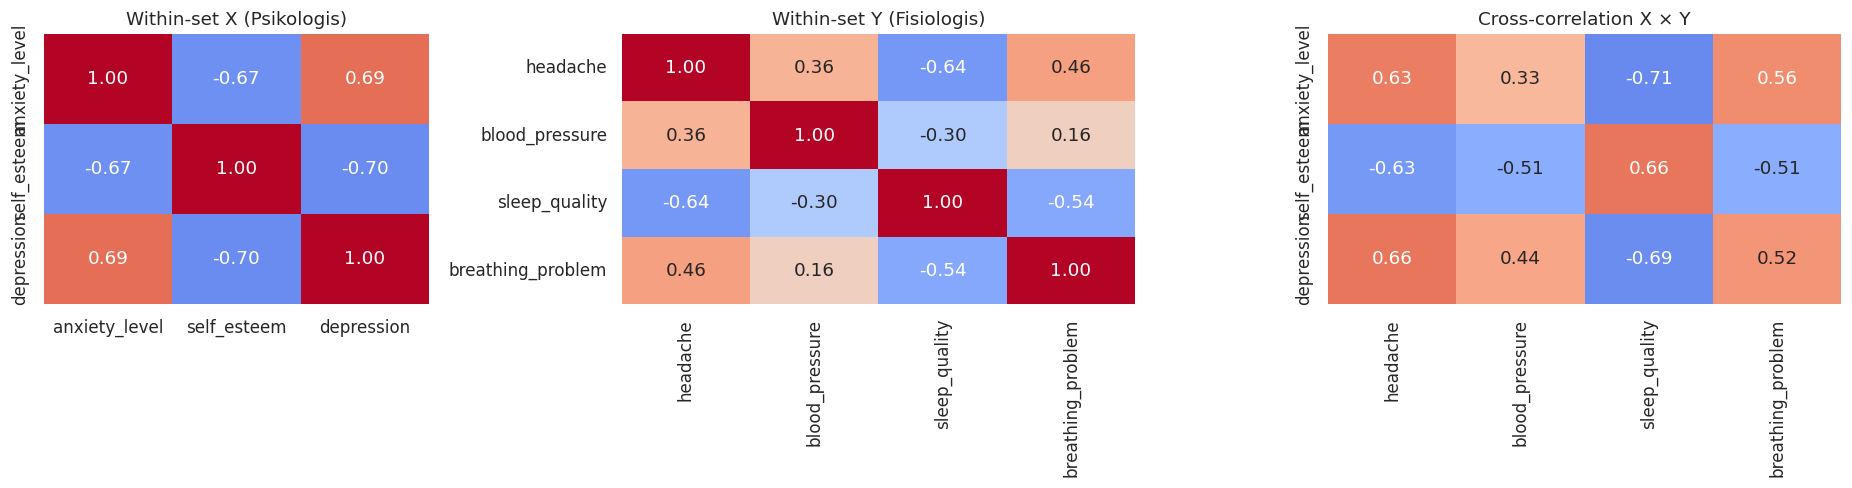

Within-X :
                anxiety_level  self_esteem  depression
anxiety_level          1.000       -0.673       0.694
self_esteem           -0.673        1.000      -0.700
depression             0.694       -0.700       1.000 

Within-Y :
                    headache  blood_pressure  sleep_quality  breathing_problem
headache              1.000           0.362         -0.639              0.462
blood_pressure        0.362           1.000         -0.300              0.162
sleep_quality        -0.639          -0.300          1.000             -0.542
breathing_problem     0.462           0.162         -0.542              1.000 

Cross X×Y :
                headache  blood_pressure  sleep_quality  breathing_problem
anxiety_level     0.633           0.331         -0.710              0.562
self_esteem      -0.626          -0.515          0.663             -0.511
depression        0.658           0.436         -0.693              0.523

Rata-rata |r| within-X = 0.689 | within-Y = 0.411 | cros

In [34]:
Rxx = pd.DataFrame(np.corrcoef(Zx, rowvar=False), index=X_VARS, columns=X_VARS)
Ryy = pd.DataFrame(np.corrcoef(Zy, rowvar=False), index=Y_VARS, columns=Y_VARS)
Rxy = pd.DataFrame(np.corrcoef(Zx, Zy, rowvar=False)[:len(X_VARS), len(X_VARS):], index=X_VARS, columns=Y_VARS)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [3, 4, 4]})
for ax, M, t in zip(axes, [Rxx, Ryy, Rxy], ["Within-set X (Psikologis)", "Within-set Y (Fisiologis)", "Cross-correlation X × Y"]):
    sns.heatmap(M, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar=False, square=False)
    ax.set_title(t)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_korelasi.png", bbox_inches="tight"); plt.show()

print("Within-X :\n", Rxx.round(3), "\n\nWithin-Y :\n", Ryy.round(3), "\n\nCross X×Y :\n", Rxy.round(3))
a_in = Rxx.values[np.triu_indices(len(X_VARS), 1)]; b_in = Ryy.values[np.triu_indices(len(Y_VARS), 1)]
print(f"\nRata-rata |r| within-X = {np.abs(a_in).mean():.3f} | within-Y = {np.abs(b_in).mean():.3f} | cross = {np.abs(Rxy.values).mean():.3f}")

### CCA

In [35]:
def inv_sqrt(M):
    w, V = np.linalg.eigh(M)
    return V @ np.diag(w ** -0.5) @ V.T

def cca_fit(X, Y):
    # CCA via SVD pada data mentah X (n x p), Y (n x q). Standardisasi dilakukan di dalam fungsi.
    n, p = X.shape; q = Y.shape[1]; m = min(p, q)
    mx, sx, my, sy = X.mean(0), X.std(0, ddof=1), Y.mean(0), Y.std(0, ddof=1)
    Zx, Zy = (X - mx) / sx, (Y - my) / sy
    Rxx, Ryy, Rxy = Zx.T @ Zx / (n - 1), Zy.T @ Zy / (n - 1), Zx.T @ Zy / (n - 1)
    U, s, Vt = np.linalg.svd(inv_sqrt(Rxx) @ Rxy @ inv_sqrt(Ryy))
    A = inv_sqrt(Rxx) @ U[:, :m]
    B = inv_sqrt(Ryy) @ Vt.T[:, :m]
    rho = np.clip(s[:m], 0, 1)
    LX, LY = Rxx @ A, Ryy @ B                       # canonical loadings (korelasi variabel asli dengan skornya sendiri)
    for k in range(m):                              # konvensi tanda: loading X terbesar bernilai positif
        if LX[np.argmax(np.abs(LX[:, k])), k] < 0:
            A[:, k] *= -1; B[:, k] *= -1
    LX, LY = Rxx @ A, Ryy @ B
    return dict(rho=rho, A=A, B=B, LX=LX, LY=LY, Rxx=Rxx, Ryy=Ryy, Rxy=Rxy,
                mx=mx, sx=sx, my=my, sy=sy, n=n, p=p, q=q, m=m)

def scores(res, X, Y):
    # skor kanonik memakai mean/std dari data pelatihan (res)
    return ((X - res["mx"]) / res["sx"]) @ res["A"], ((Y - res["my"]) / res["sy"]) @ res["B"]

res = cca_fit(X, Y)
U_sc, V_sc = scores(res, X, Y)
print("CCA selesai. Jumlah fungsi kanonik:", res["m"])

CCA selesai. Jumlah fungsi kanonik: 3


### Canonical functions maksimum

In [36]:
p, q, n = res["p"], res["q"], res["n"]
print(f"Jumlah fungsi kanonik maksimum = min(p, q) = min({p}, {q}) = {min(p, q)}")

Jumlah fungsi kanonik maksimum = min(p, q) = min(3, 4) = 3


### Canonical correlations & squared canonical correlations

,Canonical Correlation (ρ),Squared (ρ²),Cumulative ρ²
Function 1,0.8668,0.7513,0.9099
Function 2,0.2665,0.0710,0.9960
Function 3,0.0577,0.0033,1.0000


Verifikasi sklearn  ρ = [0.8668 0.2665 0.0577] | manual ρ = [0.8668 0.2665 0.0577]


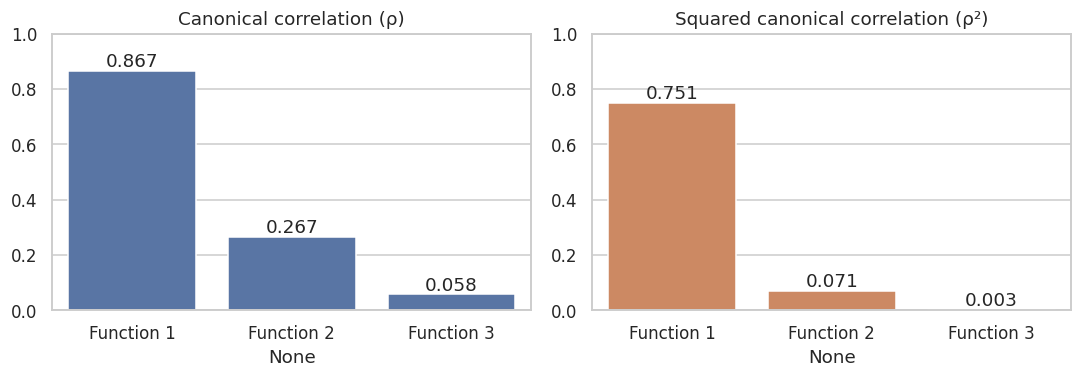

In [37]:
rho = res["rho"]
cc_tab = pd.DataFrame({"Canonical Correlation (ρ)": rho, "Squared (ρ²)": rho**2,
                       "Cumulative ρ²": np.cumsum(rho**2) / np.sum(rho**2)},
                      index=[f"Function {k+1}" for k in range(res["m"])])
display(cc_tab.round(4))

# Verifikasi silang dengan scikit-learn
sk = CCA(n_components=res["m"], scale=True, max_iter=5000, tol=1e-12).fit(X, Y)
Us, Vs = sk.transform(X, Y)
rho_sk = np.array([np.corrcoef(Us[:, k], Vs[:, k])[0, 1] for k in range(res["m"])])
print("Verifikasi sklearn  ρ =", np.round(rho_sk, 4), "| manual ρ =", np.round(rho, 4))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
sns.barplot(x=cc_tab.index, y=rho, ax=ax[0], color="#4C72B0"); ax[0].set_title("Canonical correlation (ρ)"); ax[0].set_ylim(0, 1)
sns.barplot(x=cc_tab.index, y=rho**2, ax=ax[1], color="#DD8452"); ax[1].set_title("Squared canonical correlation (ρ²)"); ax[1].set_ylim(0, 1)
for a_ in ax:
    for c in a_.containers: a_.bar_label(c, fmt="%.3f")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_canonical_corr.png", bbox_inches="tight"); plt.show()

### Pertimbangan Fungsi

In [38]:
def wilks_table(rho, n, p, q):
    rows = []
    for k in range(1, len(rho) + 1):
        lam = np.prod(1 - rho[k-1:] ** 2)
        pk, qk = p - k + 1, q - k + 1
        df1 = pk * qk
        chi2 = -(n - 1 - (p + q + 1) / 2) * np.log(lam)
        den = pk**2 + qk**2 - 5
        s = np.sqrt((pk**2 * qk**2 - 4) / den) if den > 0 else 1.0
        df2 = s * ((n - 1) - (p + q + 1) / 2) - df1 / 2 + 1
        F = (1 - lam ** (1/s)) / lam ** (1/s) * df2 / df1
        rows.append(dict(Test=f"Fungsi {k} s/d {len(rho)}", Wilks_Lambda=lam, Chi2=chi2, df=df1,
                         p_Chi2=stats.chi2.sf(chi2, df1), F_Rao=F, df1=df1, df2=df2, p_F=stats.f.sf(F, df1, df2)))
    return pd.DataFrame(rows)

wt = wilks_table(rho, n, p, q)
wt.round(5)

,Test,Wilks_Lambda,Chi2,df,p_Chi2,F_Rao,df1,df2,p_F
0,Fungsi 1 s/d 3,0.23028,1607.98412,12,0.00000,178.82757,12,2892.09769,0.00000
1,Fungsi 2 s/d 3,0.92589,84.31975,6,0.00000,14.31425,6,2188.00000,0.00000
2,Fungsi 3 s/d 3,0.99668,3.64630,2,0.16152,1.82619,2,1095.00000,0.16152



### Canonical weights


In [39]:
fn = [f"Function {k+1}" for k in range(res["m"])]
W_X = pd.DataFrame(res["A"], index=X_VARS, columns=fn)
W_Y = pd.DataFrame(res["B"], index=Y_VARS, columns=fn)
print("Canonical weights — Set X (Psikologis)"); display(W_X.round(3))
print("Canonical weights — Set Y (Fisiologis)"); display(W_Y.round(3))

Canonical weights — Set X (Psikologis)


,Function 1,Function 2,Function 3
anxiety_level,0.353,1.278,-0.684
self_esteem,-0.384,1.190,0.833
depression,0.386,-0.070,1.494


Canonical weights — Set Y (Fisiologis)


,Function 1,Function 2,Function 3
headache,0.316,0.082,1.115
blood_pressure,0.259,-1.011,-0.265
sleep_quality,-0.483,-0.421,0.208
breathing_problem,0.238,0.174,-0.858


### Canonical loadings

Canonical loadings — Set X


,Function 1,Function 2,Function 3
anxiety_level,0.879,0.429,-0.207
self_esteem,-0.891,0.379,0.248
depression,0.900,-0.015,0.436


Canonical loadings — Set Y


,Function 1,Function 2,Function 3
headache,0.828,0.065,0.490
blood_pressure,0.557,-0.826,-0.063
sleep_quality,-0.892,-0.264,0.040
breathing_problem,0.688,0.276,-0.499


Cek loading X = corr(Zx, U): True


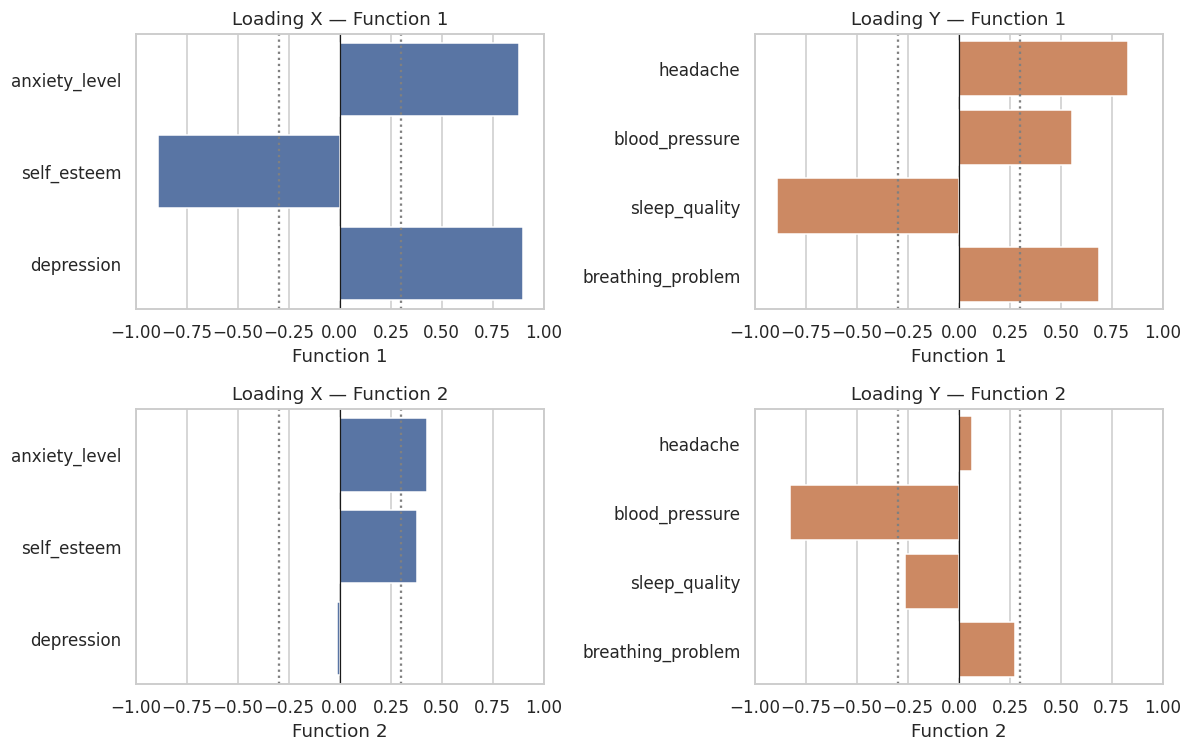

In [40]:
L_X = pd.DataFrame(res["LX"], index=X_VARS, columns=fn)
L_Y = pd.DataFrame(res["LY"], index=Y_VARS, columns=fn)
print("Canonical loadings — Set X"); display(L_X.round(3))
print("Canonical loadings — Set Y"); display(L_Y.round(3))

# Verifikasi: loading memang = korelasi variabel asli dengan skor kanonik
chk = np.corrcoef(Zx, U_sc, rowvar=False)[:p, p:]
print("Cek loading X = corr(Zx, U):", np.allclose(chk, res["LX"], atol=1e-8))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for k in range(min(2, res["m"])):
    sns.barplot(x=L_X.iloc[:, k], y=X_VARS, ax=axes[k, 0], color="#4C72B0"); axes[k, 0].set_title(f"Loading X — Function {k+1}")
    sns.barplot(x=L_Y.iloc[:, k], y=Y_VARS, ax=axes[k, 1], color="#DD8452"); axes[k, 1].set_title(f"Loading Y — Function {k+1}")
    for a_ in axes[k]: a_.set_xlim(-1, 1); a_.axvline(0, color="k", lw=.8); a_.axvline(.3, color="grey", ls=":"); a_.axvline(-.3, color="grey", ls=":")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_loadings.png", bbox_inches="tight"); plt.show()

### Cross-loadings

In [41]:
CL_X = L_X * rho     # variabel X dengan variat Y (V_k)
CL_Y = L_Y * rho     # variabel Y dengan variat X (U_k)
print("Cross-loadings — Set X terhadap variat Y"); display(CL_X.round(3))
print("Cross-loadings — Set Y terhadap variat X"); display(CL_Y.round(3))

chk2 = np.corrcoef(Zx, V_sc, rowvar=False)[:p, p:]
print("Cek cross-loading X = corr(Zx, V):", np.allclose(chk2, CL_X.values, atol=1e-8))

Cross-loadings — Set X terhadap variat Y


,Function 1,Function 2,Function 3
anxiety_level,0.762,0.114,-0.012
self_esteem,-0.773,0.101,0.014
depression,0.780,-0.004,0.025


Cross-loadings — Set Y terhadap variat X


,Function 1,Function 2,Function 3
headache,0.718,0.017,0.028
blood_pressure,0.483,-0.220,-0.004
sleep_quality,-0.773,-0.070,0.002
breathing_problem,0.596,0.074,-0.029


Cek cross-loading X = corr(Zx, V): True


### Variance Extracted & Redundancy


In [42]:
VE_X = (L_X ** 2).mean(0); VE_Y = (L_Y ** 2).mean(0)
RD_X = VE_X * rho**2      # varians X yang dijelaskan variat Y
RD_Y = VE_Y * rho**2      # varians Y yang dijelaskan variat X

ve_rd = pd.DataFrame({
    "VE_X": VE_X.values, "VE_Y": VE_Y.values,
    "Redundancy X|Y": RD_X.values, "Redundancy Y|X": RD_Y.values,
    "Cum. Redundancy X|Y": np.cumsum(RD_X.values), "Cum. Redundancy Y|X": np.cumsum(RD_Y.values)}, index=fn)
display(ve_rd.round(4))
print(f"Total VE_X = {VE_X.sum():.3f} | Total VE_Y = {VE_Y.sum():.3f}  (bila semua fungsi dipakai, VE_X dan VE_Y masing-masing berjumlah m/p dan m/q)")
print(f"Total redundancy X|Y = {RD_X.sum():.4f} | Total redundancy Y|X = {RD_Y.sum():.4f}")

,VE_X,VE_Y,Redundancy X|Y,Redundancy Y|X,Cum. Redundancy X|Y,Cum. Redundancy Y|X
Function 1,0.7925,0.5658,0.5954,0.4251,0.5954,0.4251
Function 2,0.1093,0.2083,0.0078,0.0148,0.6032,0.4399
Function 3,0.0982,0.1237,0.0003,0.0004,0.6035,0.4403


Total VE_X = 1.000 | Total VE_Y = 0.898  (bila semua fungsi dipakai, VE_X dan VE_Y masing-masing berjumlah m/p dan m/q)
Total redundancy X|Y = 0.6035 | Total redundancy Y|X = 0.4403


### Significance testing & empirical validation


Permutation test (global Wilks Λ): p = 0.0005
p-value permutasi per fungsi (ρ_k vs distribusi nol ρ_k): [0.0005 0.0005 0.0055]


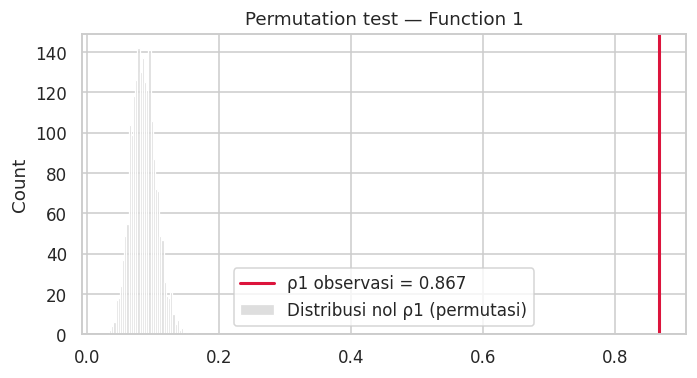

In [43]:
# (b) PERMUTATION TEST — acak baris Y untuk memutus hubungan X–Y
def permutation_test(X, Y, n_perm=N_PERM, seed=1):
    rng = np.random.default_rng(seed)
    obs = cca_fit(X, Y)["rho"]
    lam_obs = np.prod(1 - obs ** 2)
    perm_rho = np.empty((n_perm, len(obs)))
    for b in range(n_perm):
        perm_rho[b] = cca_fit(X, Y[rng.permutation(len(Y))])["rho"]
    lam_perm = np.prod(1 - perm_rho ** 2, axis=1)
    p_global = (np.sum(lam_perm <= lam_obs) + 1) / (n_perm + 1)
    p_each = [(np.sum(perm_rho[:, k] >= obs[k]) + 1) / (n_perm + 1) for k in range(len(obs))]
    return p_global, p_each, perm_rho

p_glob, p_each, perm_rho = permutation_test(X, Y)
print(f"Permutation test (global Wilks Λ): p = {p_glob:.4f}")
print("p-value permutasi per fungsi (ρ_k vs distribusi nol ρ_k):", np.round(p_each, 4))

plt.figure(figsize=(6.5, 3.6))
sns.histplot(perm_rho[:, 0], bins=40, color="lightgrey", label="Distribusi nol ρ1 (permutasi)")
plt.axvline(rho[0], color="crimson", lw=2, label=f"ρ1 observasi = {rho[0]:.3f}")
plt.legend(); plt.title("Permutation test — Function 1"); plt.tight_layout()
plt.savefig(f"{OUT}/fig_permutation.png", bbox_inches="tight"); plt.show()

In [44]:
# (c) BOOTSTRAP — CI korelasi kanonik & stabilitas loading
def align(res_b, ref):
    # cocokkan fungsi hasil bootstrap ke fungsi asli (urutan bisa tertukar; tanda bisa terbalik)
    m = ref["m"]
    S = np.zeros((m, m)); sg = np.zeros((m, m))
    for i in range(m):
        for j in range(m):
            dx = ref["LX"][:, i] @ res_b["LX"][:, j]; dy = ref["LY"][:, i] @ res_b["LY"][:, j]
            S[i, j] = abs(dx) + abs(dy); sg[i, j] = np.sign(dx + dy) or 1.0
    r, c = linear_sum_assignment(-S)
    order = c[np.argsort(r)]; sign = sg[np.arange(m), order]
    return order, sign

def bootstrap_cca(X, Y, ref, n_boot=N_BOOT, seed=2):
    rng = np.random.default_rng(seed)
    m, p_, q_ = ref["m"], ref["p"], ref["q"]
    rho_b = np.empty((n_boot, m)); LX_b = np.empty((n_boot, p_, m)); LY_b = np.empty((n_boot, q_, m))
    for b in range(n_boot):
        idx = rng.integers(0, len(X), len(X))
        rb = cca_fit(X[idx], Y[idx])
        order, sign = align(rb, ref)
        rho_b[b] = rb["rho"][order]
        LX_b[b] = rb["LX"][:, order] * sign; LY_b[b] = rb["LY"][:, order] * sign
    return rho_b, LX_b, LY_b

rho_b, LX_b, LY_b = bootstrap_cca(X, Y, res)
ci = pd.DataFrame({"ρ": rho, "Boot mean": rho_b.mean(0), "SE": rho_b.std(0, ddof=1),
                   "CI 2.5%": np.percentile(rho_b, 2.5, axis=0), "CI 97.5%": np.percentile(rho_b, 97.5, axis=0)}, index=fn)
display(ci.round(4))

def loading_ci(L_b, names, ref_L):
    lo, hi = np.percentile(L_b, 2.5, axis=0), np.percentile(L_b, 97.5, axis=0)
    out = {}
    for k in range(ref_L.shape[1]):
        out[fn[k]] = pd.DataFrame({"loading": ref_L[:, k], "CI 2.5%": lo[:, k], "CI 97.5%": hi[:, k],
                                   "stabil (CI tak memuat 0)": (lo[:, k] > 0) | (hi[:, k] < 0)}, index=names)
    return out

lci_x = loading_ci(LX_b, X_VARS, res["LX"]); lci_y = loading_ci(LY_b, Y_VARS, res["LY"])
print("\nBootstrap CI loading Function 1 — X"); display(lci_x[fn[0]].round(3))
print("Bootstrap CI loading Function 1 — Y"); display(lci_y[fn[0]].round(3))
if res["m"] >= 2:
    print("Bootstrap CI loading Function 2 — X"); display(lci_x[fn[1]].round(3))
    print("Bootstrap CI loading Function 2 — Y"); display(lci_y[fn[1]].round(3))

,ρ,Boot mean,SE,CI 2.5%,CI 97.5%
Function 1,0.8668,0.8680,0.0109,0.8468,0.8889
Function 2,0.2665,0.2768,0.0298,0.2181,0.3349
Function 3,0.0577,0.0739,0.0348,0.0157,0.1477



Bootstrap CI loading Function 1 — X


,loading,CI 2.5%,CI 97.5%,stabil (CI tak memuat 0)
anxiety_level,0.879,0.848,0.905,True
self_esteem,-0.891,-0.914,-0.863,True
depression,0.900,0.876,0.922,True


Bootstrap CI loading Function 1 — Y


,loading,CI 2.5%,CI 97.5%,stabil (CI tak memuat 0)
headache,0.828,0.796,0.859,True
blood_pressure,0.557,0.521,0.590,True
sleep_quality,-0.892,-0.913,-0.866,True
breathing_problem,0.688,0.648,0.723,True


Bootstrap CI loading Function 2 — X


,loading,CI 2.5%,CI 97.5%,stabil (CI tak memuat 0)
anxiety_level,0.429,0.345,0.491,True
self_esteem,0.379,0.284,0.457,True
depression,-0.015,-0.143,0.110,False


Bootstrap CI loading Function 2 — Y


,loading,CI 2.5%,CI 97.5%,stabil (CI tak memuat 0)
headache,0.065,-0.138,0.272,False
blood_pressure,-0.826,-0.842,-0.720,True
sleep_quality,-0.264,-0.380,-0.103,True
breathing_problem,0.276,0.033,0.491,True


,ρ (full sample),ρ train (rata-rata),ρ test (rata-rata),SD test,Penyusutan (train − test)
Function 1,0.8668,0.8671,0.8642,0.0227,0.0029
Function 2,0.2665,0.2687,0.2463,0.0657,0.0225
Function 3,0.0577,0.0621,0.0058,0.0835,0.0563


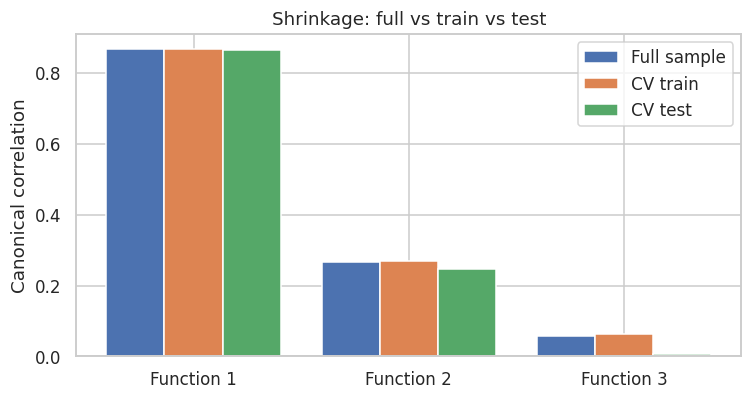

In [45]:
# (d) REPEATED K-FOLD CROSS-VALIDATION — bobot dilatih di training, korelasi dievaluasi di data uji
def cv_cca(X, Y, n_splits=5, n_repeats=20, seed=3):
    rkf = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    tr, te = [], []
    for i_tr, i_te in rkf.split(X):
        r = cca_fit(X[i_tr], Y[i_tr])
        u_tr, v_tr = scores(r, X[i_tr], Y[i_tr]); u_te, v_te = scores(r, X[i_te], Y[i_te])
        tr.append([np.corrcoef(u_tr[:, k], v_tr[:, k])[0, 1] for k in range(r["m"])])
        te.append([np.corrcoef(u_te[:, k], v_te[:, k])[0, 1] for k in range(r["m"])])
    return np.array(tr), np.array(te)

tr_cv, te_cv = cv_cca(X, Y)
cv_tab = pd.DataFrame({"ρ (full sample)": rho, "ρ train (rata-rata)": tr_cv.mean(0),
                       "ρ test (rata-rata)": te_cv.mean(0), "SD test": te_cv.std(0, ddof=1),
                       "Penyusutan (train − test)": tr_cv.mean(0) - te_cv.mean(0)}, index=fn)
display(cv_tab.round(4))

fig, ax = plt.subplots(figsize=(7, 3.8))
xk = np.arange(res["m"]); w = .27
ax.bar(xk - w, rho, w, label="Full sample"); ax.bar(xk, tr_cv.mean(0), w, label="CV train"); ax.bar(xk + w, te_cv.mean(0), w, label="CV test")
ax.set_xticks(xk); ax.set_xticklabels(fn); ax.set_ylabel("Canonical correlation"); ax.legend(); ax.set_title("Shrinkage: full vs train vs test")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_cv.png", bbox_inches="tight"); plt.show()

In [46]:
# (e) ROBUSTNESS — CCA pada data yang di-rank-transform (kurang sensitif terhadap skala ordinal/outlier)
Xr = pd.DataFrame(X).rank().to_numpy(); Yr = pd.DataFrame(Y).rank().to_numpy()
res_r = cca_fit(Xr, Yr)
print("ρ data asli       :", np.round(rho, 4)); print("ρ data rank (Spearman-type):", np.round(res_r["rho"], 4))

# (f) VALIDASI EKSTERNAL — hubungkan skor kanonik dengan stress_level (tidak dipakai dalam CCA)
if EXTERNAL_VAR in data.columns:
    ext = data[EXTERNAL_VAR].to_numpy()
    ext_tab = pd.DataFrame({
        "Spearman(U_k, stress_level)": [stats.spearmanr(U_sc[:, k], ext)[0] for k in range(res["m"])],
        "Spearman(V_k, stress_level)": [stats.spearmanr(V_sc[:, k], ext)[0] for k in range(res["m"])]}, index=fn)
    display(ext_tab.round(3))

ρ data asli       : [0.8668 0.2665 0.0577]
ρ data rank (Spearman-type): [0.8757 0.1774 0.0668]


,"Spearman(U_k, stress_level)","Spearman(V_k, stress_level)"
Function 1,0.819,0.818
Function 2,0.031,0.250
Function 3,-0.031,0.052


### Ringkasan keputusan — fungsi yang layak

In [47]:
summary = pd.DataFrame({
    "ρ": rho, "ρ²": rho**2, "p Wilks (Rao F)": wt["p_F"].values, "p permutasi": p_each,
    "Boot CI 2.5%": ci["CI 2.5%"].values, "ρ test CV": te_cv.mean(0),
    "Redundancy X|Y": RD_X.values, "Redundancy Y|X": RD_Y.values}, index=fn)
summary["Layak?"] = ((summary["p Wilks (Rao F)"] < ALPHA) & (summary["p permutasi"] < ALPHA) &
                     (summary["ρ²"] >= MIN_R2) & (summary["ρ test CV"] >= MIN_CV)).map({True: "YA", False: "TIDAK"})
display(summary.round(4))
summary.round(4).to_csv(f"{OUT}/tabel_ringkasan_cca.csv")
retained = [i + 1 for i, v in enumerate(summary["Layak?"]) if v == "YA"]
print("Fungsi yang layak diinterpretasi:", retained or "tidak ada")

,ρ,ρ²,p Wilks (Rao F),p permutasi,Boot CI 2.5%,ρ test CV,Redundancy X|Y,Redundancy Y|X,Layak?
Function 1,0.8668,0.7513,0.0000,0.0005,0.8468,0.8642,0.5954,0.4251,YA
Function 2,0.2665,0.0710,0.0000,0.0005,0.2181,0.2463,0.0078,0.0148,TIDAK
Function 3,0.0577,0.0033,0.1615,0.0055,0.0157,0.0058,0.0003,0.0004,TIDAK


Fungsi yang layak diinterpretasi: [1]


### Visualisasi skor kanonik

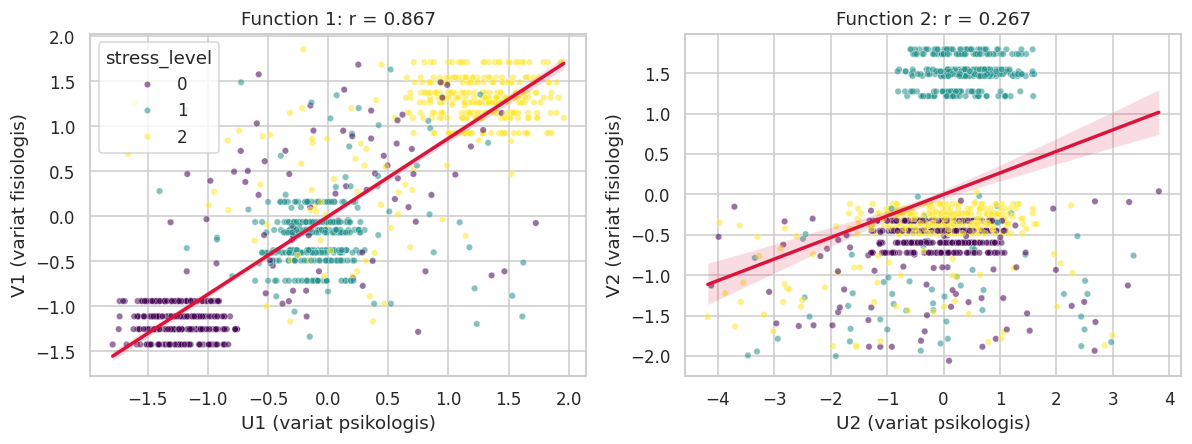

In [48]:
fig, axes = plt.subplots(1, min(2, res["m"]), figsize=(11, 4.2))
axes = np.atleast_1d(axes)
for k, ax in enumerate(axes):
    hue = data[EXTERNAL_VAR] if EXTERNAL_VAR in data.columns else None
    sns.scatterplot(x=U_sc[:, k], y=V_sc[:, k], hue=hue, palette="viridis", alpha=.55, s=18, ax=ax, legend=(k == 0))
    sns.regplot(x=U_sc[:, k], y=V_sc[:, k], scatter=False, color="crimson", ax=ax)
    ax.set_xlabel(f"U{k+1} (variat psikologis)"); ax.set_ylabel(f"V{k+1} (variat fisiologis)")
    ax.set_title(f"Function {k+1}: r = {rho[k]:.3f}")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_skor_kanonik.png", bbox_inches="tight"); plt.show()

### RIngkasan Hasil

In [49]:
def describe_function(k, thr=0.30):
    # ringkas variabel dominan (|loading| >= thr) beserta arahnya
    def side(L, names):
        items = [(n_, L[i, k]) for i, n_ in enumerate(names) if abs(L[i, k]) >= thr]
        items.sort(key=lambda t: -abs(t[1]))
        return ", ".join(f"{n_} ({l:+.2f})" for n_, l in items) or "(tidak ada loading >= %.2f)" % thr
    strength = "kuat" if rho[k] >= .7 else "sedang" if rho[k] >= .4 else "lemah"
    print(f"FUNCTION {k+1}")
    print(f"  Korelasi kanonik ρ = {rho[k]:.3f} ({strength}); ρ² = {rho[k]**2:.3f} -> {rho[k]**2*100:.1f}% varians bersama antar-variat")
    print(f"  Variat psikologis (U{k+1}) didominasi : {side(res['LX'], X_VARS)}")
    print(f"  Variat fisiologis (V{k+1}) didominasi : {side(res['LY'], Y_VARS)}")
    print(f"  Variance extracted X={VE_X.iloc[k]:.3f}, Y={VE_Y.iloc[k]:.3f} | Redundancy X|Y={RD_X.iloc[k]:.3f}, Y|X={RD_Y.iloc[k]:.3f}")
    print("  Layak dipertimbangkan:", summary['Layak?'].iloc[k], "\n")

for k in range(res["m"]):
    describe_function(k)

FUNCTION 1
  Korelasi kanonik ρ = 0.867 (kuat); ρ² = 0.751 -> 75.1% varians bersama antar-variat
  Variat psikologis (U1) didominasi : depression (+0.90), self_esteem (-0.89), anxiety_level (+0.88)
  Variat fisiologis (V1) didominasi : sleep_quality (-0.89), headache (+0.83), breathing_problem (+0.69), blood_pressure (+0.56)
  Variance extracted X=0.793, Y=0.566 | Redundancy X|Y=0.595, Y|X=0.425
  Layak dipertimbangkan: YA 

FUNCTION 2
  Korelasi kanonik ρ = 0.267 (lemah); ρ² = 0.071 -> 7.1% varians bersama antar-variat
  Variat psikologis (U2) didominasi : anxiety_level (+0.43), self_esteem (+0.38)
  Variat fisiologis (V2) didominasi : blood_pressure (-0.83)
  Variance extracted X=0.109, Y=0.208 | Redundancy X|Y=0.008, Y|X=0.015
  Layak dipertimbangkan: TIDAK 

FUNCTION 3
  Korelasi kanonik ρ = 0.058 (lemah); ρ² = 0.003 -> 0.3% varians bersama antar-variat
  Variat psikologis (U3) didominasi : depression (+0.44)
  Variat fisiologis (V3) didominasi : breathing_problem (-0.50), headache